> **Notebook exploratório — não faz parte dos resultados do artigo.**
>
> Checagem auxiliar da acurácia do MapBiomas para o Brasil inteiro. As saídas foram limpas porque a versão salva
> anteriormente vinha de uma execução fora de ordem. Pendência conhecida: `dados/completo_acc_mapbiomas_80_2022.csv`
> não tem a coluna `strata_id`, então o merge com `dados/strata.csv` falha e as estatísticas por estrato não são calculadas.


# Avaliação de desempenho

Esse bate corrretamente com o que é gerado pelo codigo do repositorio

## Imports

In [ ]:
import pandas as pd
import numpy as np
import json


## Parâmetros e configurações

In [ ]:
level = 'l1'
path_acc = '../dados/completo_acc_mapbiomas_80_2022.csv'
path_class_settings = '../dados/config_classes.json'
path_strata = '../dados/strata.csv'

ficar identico ao gerado pelo algoritmo do mapbiomas

In [ ]:
IGNORED_CLASSES = [0]
ALL_CLASSES = {
    0: {
        "l1_val": 0,
        "l1": "6. Não Observado",
        "l2_val": 0,
        "l2": "6. Não Observado",
        "l3_val": 0,
        "l3": "6. Não Observado"
    },
    3: {
        "l1_val": 1,
        "l1": "1. Floresta",
        "l2_val": 3,
        "l2": "1.1. Formação Florestal",
        "l3_val": 3,
        "l3": "1.1. Formação Florestal"
    },
    4: {
        "l1_val": 1,
        "l1": "1. Floresta",
        "l2_val": 4,
        "l2": "1.2. Formação Savânica",
        "l3_val": 4,
        "l3": "1.2. Formação Savânica"
    },
    5: {
        "l1_val": 1,
        "l1": "1. Floresta",
        "l2_val": 5,
        "l2": "1.3. Mangue",
        "l3_val": 5,
        "l3": "1.3. Mangue"
    },
    9: {
        "l1_val": 14,
        "l1": "3. Agropecuária",
        "l2_val": 9,
        "l2": "3.3. Floresta Plantada",
        "l3_val": 9,
        "l3": "3.3. Floresta Plantada"
    },
    11: {
        "l1_val": 10,
        "l1": "2. Formação Natural não Florestal",
        "l2_val": 11,
        "l2": "2.1. Campo Alagado e Área Pantanosa",
        "l3_val": 11,
        "l3": "2.1. Campo Alagado e Área Pantanosa"
    },
    12: {
        "l1_val": 10,
        "l1": "2. Formação Natural não Florestal",
        "l2_val": 12,
        "l2": "2.2. Formação Campestre (Campo)",
        "l3_val": 12,
        "l3": "2.2. Formação Campestre (Campo)"
    },
    13: {
        "l1_val": 10,
        "l1": "2. Formação Natural não Florestal",
        "l2_val": 13,
        "l2": "2.6. Outra Formação não Florestal",
        "l3_val": 13,
        "l3": "2.6. Outra Formação não Florestal"
    },
    15: {
        "l1_val": 14,
        "l1": "3. Agropecuária",
        "l2_val": 15,
        "l2": "3.1. Pastagem",
        "l3_val": 15,
        "l3": "3.1. Pastagem"
    },
    19: {
        "l1_val": 14,
        "l1": "3. Agropecuária",
        "l2_val": 18,
        "l2": "3.2. Agricultura",
        "l3_val": 19,
        "l3": "3.2.1. Lavoura Temporária"
    },
    20: {
        "l1_val": 14,
        "l1": "3. Agropecuária",
        "l2_val": 18,
        "l2": "3.2. Agricultura",
        "l3_val": 20,
        "l3": "3.2.2. Lavoura Perene"
    },
    21: {
        "l1_val": 14,
        "l1": "3. Agropecuária",
        "l2_val": 21,
        "l2": "3.4. Mosaico de Usos",
        "l3_val": 21,
        "l3": "3.4. Mosaico de Usos"
    },
    23: {
        "l1_val": 22,
        "l1": "4. Área não Vegetada",
        "l2_val": 23,
        "l2": "4.1. Praia e Duna",
        "l3_val": 23,
        "l3": "4.1. Praia e Duna"
    },
    24: {
        "l1_val": 22,
        "l1": "4. Área não Vegetada",
        "l2_val": 24,
        "l2": "4.2. Infraestrutura Urbana",
        "l3_val": 24,
        "l3": "4.2. Infraestrutura Urbana"
    },
    25: {
        "l1_val": 22,
        "l1": "4. Área não Vegetada",
        "l2_val": 25,
        "l2": "4.4. Outra Área não Vegetada",
        "l3_val": 25,
        "l3": "4.4. Outra Área não Vegetada"
    },
    29: {
        "l1_val": 10,
        "l1": "2. Formação Natural não Florestal",
        "l2_val": 29,
        "l2": "2.4. Afloramento Rochoso",
        "l3_val": 29,
        "l3": "2.4. Afloramento Rochoso"
    },
    30: {
        "l1_val": 22,
        "l1": "4. Área não Vegetada",
        "l2_val": 30,
        "l2": "4.3. Mineração",
        "l3_val": 30,
        "l3": "4.3. Mineração"
    },
    31: {
        "l1_val": 26,
        "l1": "5. Corpo D'água",
        "l2_val": 63,
        "l2": "5.2. Corpos D'Água Artificiais",
        "l3_val": 31,
        "l3": "5.2. Aquicultura"
    },
    32: {
        "l1_val": 10,
        "l1": "2. Formação Natural não Florestal",
        "l2_val": 32,
        "l2": "2.3. Apicum",
        "l3_val": 32,
        "l3": "2.3. Apicum"
    },
    33: {
        "l1_val": 26,
        "l1": "5. Corpo D'água",
        "l2_val": 33,
        "l2": "5.1. Rio, Lago e Oceano",
        "l3_val": 33,
        "l3": "5.1. Rio, Lago e Oceano"
    },
    36: {
        "l1_val": 14,
        "l1": "3. Agropecuária",
        "l2_val": 18,
        "l2": "3.2. Agricultura",
        "l3_val": 36,
        "l3": "3.2.2. Lavoura Perene"
    },
    39: {
        "l1_val": 14,
        "l1": "3. Agropecuária",
        "l2_val": 18,
        "l2": "3.2. Agricultura",
        "l3_val": 19,
        "l3": "3.2.1. Lavoura Temporária",
        #"l4_val": 39,
        #"l4": "3.2.2.1. Soja"
    },
    40: {
        "l1_val": 14,
        "l1": "3. Agropecuária",
        "l2_val": 18,
        "l2": "3.2. Agricultura",
        "l3_val": 19,
        "l3": "3.2.1. Lavoura Temporária",
        #"l4_val": 40,
        #"l4": "3.2.2.3. Arroz"
    },
    41: {
        "l1_val": 14,
        "l1": "3. Agropecuária",
        "l2_val": 18,
        "l2": "3.2. Agricultura",
        "l3_val": 19,
        "l3": "3.2.1. Lavoura Temporária",
        #"l4_val": 41,
        #"l4": "3.2.1.3. Outras Lavouras Temporárias"
    },
    46: {
        "l1_val": 14,
        "l1": "3. Agropecuária",
        "l2_val": 18,
        "l2": "3.2. Agricultura",
        "l3_val": 19,
        "l3": "3.2.1. Lavoura Temporária",
        #"l4_val": 46,
        #"l4": "3.2.1.1. Café"
    },
    47: {
        "l1_val": 14,
        "l1": "3. Agropecuária",
        "l2_val": 18,
        "l2": "3.2. Agricultura",
        "l3_val": 19,
        "l3": "3.2.1. Lavoura Temporária",
        #"l4_val": 47,
        #"l4": "3.2.1.2. Citrus"
    },
    48: {
        "l1_val": 14,
        "l1": "3. Agropecuária",
        "l2_val": 18,
        "l2": "3.2. Agricultura",
        "l3_val": 19,
        "l3": "3.2.1. Lavoura Temporária",
        #"l4_val": 48,
        #"l4": " 3.2.2.3. Outras Lavoura Perene"
    },
    49: {
        "l1_val": 1,
        "l1": "1. Floresta",
        "l2_val": 2,
        "l2": "1.4. Restinga Florestal",
        "l3_val": 49,
        "l3": "1.4. Restinga Florestal"
    },
    50: {
        "l1_val": 10,
        "l1": "2. Formação Natural não Florestal",
        "l2_val": 50,
        "l2": "2.5. Restinga Herbácea/Arbustiva",
        "l3_val": 50,
        "l3": "2.5. Restinga Herbácea/Arbustiva"
    },
    62: {
        "l1_val": 14,
        "l1": "3. Agropecuária",
        "l2_val": 18,
        "l2": "3.2. Agricultura",
        "l3_val": 19,
        "l3": "3.2.1. Lavoura Temporária",
        #"l4_val": 62,
        #"l4": "3.2.1.4. Algodão (beta)"
    },
    63: {
        "l1_val": 26,
        "l1": "5. Corpo D'água",
        "l2_val": 63,
        "l2": "5.2. Corpos D'Água Artificiais",
        "l3_val": 63,
        "l3": "5.2. Corpos D'Água Artificiais"
    },
}

## Entrada de dados

Arquivo com os dados de classificação e os dados de referencia de 2022, gerado no google earth engine:

https://code.earthengine.google.com/365963f4785378c21da4b24fa43061fb

so adicionado como limite o grupode de cartas SA-23-Z

In [ ]:
df_acc = pd.read_csv(path_acc)
df_acc.head()

apenas as amostras SA23-Z

In [ ]:
df_acc.shape

Configuracao com as classes

In [ ]:
with open(path_class_settings, 'r') as arquivo:
    config_classes = json.load(arquivo)
config_classes['IGNORED_CLASSES']

In [ ]:
#all_classes = config_classes['ALL_CLASSES']
#valor_removido = all_classes.pop('6')
#valor_removido

In [ ]:
#config_classes['ALL_CLASSES'] = all_classes

Para não ignorar essas classes:

In [ ]:
#config_classes['IGNORED_CLASSES'] = [0]
config_classes['IGNORED_CLASSES']

Aqui, não irei usar o arquivo points_strata.csv, pois os dados do target_id estao errados na coleção das amostras

pegarei apenas o dadoq que tem a populacao por estrato

In [ ]:
df_strata = pd.read_csv(path_strata)
df_strata.head()

In [ ]:
df_strata.shape ## todas os estratos

## Tratamento de dados

### Gerando a coluna strata_id como no codigo do mapbiomas

In [ ]:
points_strata = pd.read_csv('../dados/points_strata.csv')

In [ ]:
df = pd.merge(df_acc, points_strata, how='inner', on='TARGETID')
df.head()

### Gerando a coluna strata_id

como os estrato id estao errados nos dados que tive acesso no mapbiomas, vou criar o estrato id com base no dado do estrato e da declividade

In [ ]:
#df_acc['strata_id'] = df_acc["CARTA_2"] + "_" + df_acc["DECLIVIDAD"]

verificando os estratos

In [ ]:
#df_acc["strata_id"].unique()

### Pegando os dados dado da populacao

In [ ]:
df_acc = pd.merge(df_acc, df_strata, how='inner', on="strata_id")
df_acc.head()

In [ ]:
df_acc['pop'].head()

### Pegando a quantidade de amostras por estrato

contar a quantidade de amostras por estrato

In [ ]:
df_acc['strata_id'].value_counts(normalize=True).plot(kind='barh')

In [ ]:
df_qt_samples = df_acc['strata_id'].value_counts().reset_index(name='n_samp')
df_qt_samples

In [ ]:
df_qt_samples.sum()

depois plotar um mapa os pontos por estrato

In [ ]:
df_acc = pd.merge(df_acc, df_qt_samples, on='strata_id')
df_acc.head()

verificar se esta ok numero de amostras e populacao

In [ ]:
df_acc.columns

In [ ]:
df_contagem = df_acc.groupby("strata_id")[['n_samp','pop', 'PROB_AMOS2']].first()
df_contagem

checando a probabilidade

In [ ]:
df_contagem["prob_calc"] = df_contagem['n_samp'] / df_contagem['pop']
df_contagem

In [ ]:
df_contagem.sum()

### Atualiza o nome dos biomas, para texto

In [ ]:
df_acc.loc[ (df_acc['BioNB']==1),'BioNB'] = 'Amazônia'
df_acc.loc[ (df_acc['BioNB']==2),'BioNB'] = 'Mata Atlântica'
df_acc.loc[ (df_acc['BioNB']==3),'BioNB'] = 'Pantanal'
df_acc.loc[ (df_acc['BioNB']==4),'BioNB'] = 'Cerrado'
df_acc.loc[ (df_acc['BioNB']==5),'BioNB'] = 'Caatinga'
df_acc.loc[ (df_acc['BioNB']==6),'BioNB'] = 'Pampa'

In [ ]:
df_acc['BioNB'].unique()

### Atualizando os codigos das classes de acordo com o nivel, e outros ajustes

#### Converte codigos das classe

In [ ]:
df_acc['classification'].value_counts().sort_index()

In [ ]:
classif_1 = df_acc['classification'].unique()
classif_1.sort()
classif_1

In [ ]:
df_acc['reference'].value_counts().sort_index()

In [ ]:
reference_1 = df_acc['reference'].unique()
reference_1.sort()
reference_1

Observando a classificacao e a reference, observamos algumas classes que aparece em uma e nao na outra, porém a funcao de convert_class corrige algumas, provavelmente pq mudaram se os codigos de algumas destas. pesquisar melhor


classificacao

6 - Floresta Alagável (nivel 2)

21 - mosaico de usos (nivel 2)

39 - Soja (nivel 3)

41 - Outras Lavouras Temporárias (nivel 3)

reference

19 - Lavoura Temporária (nivel 3)

50 - Restinga Herbácea

In [ ]:
def convert_class(df):

    #Global

    df.loc[ (df['classification'] == 20) | (df['classification'] == 39) | (df['classification'] == 40) | (df['classification'] == 41) | (df['classification'] == 62), 'classification'] = 19 #Convert areas mapped as 20,39,40,41 to 19
    df.loc[ (df['classification'] == 46) | (df['classification'] == 47) | (df['classification'] == 48), 'classification'] = 36 #Convert areas mapped as 46,47,48 to 36
    df.loc[ (df['classification'] == 51) | (df['classification'] == 52) | (df['classification'] == 53), 'classification'] = 24 #Convert areas mapped as 20,39,41 to 24
    df.loc[ (df['classification'] == 49), 'classification'] = 3 #Convert areas mapped as 54,55,56 to 33
    df.loc[ (df['classification'] == 50), 'classification'] = 13 #Convert areas mapped as 54,55,56 to 33
    df.loc[ (df['classification'] == 54) | (df['classification'] == 55) | (df['classification'] == 56), 'classification'] = 33 #Convert areas mapped as 54,55,56 to 33
    df.loc[ (df['classification'] == 21) & (df['reference'].isin([15,19,20,36])), 'reference'] = 21 #Convert reference from 15,19,20,36 to reference 21 for areas mapped as 21
    df.loc[ (df['classification'] == 63), 'classification'] = 33    

    #Pampa 

    df.loc[ (df['BioNB']== 'Pampa') & (df['reference'] == 15),'reference'] = 19 #In Pampa, convert reference class 15 to 19 (Crop).
    df.loc[ (df['BioNB']=='Pampa') & (df['classification'] == 25) & (df['reference'] == 23), 'reference'] = 25 #In Pampa, convert reference 25 to 23 in areas mapped as 25
    df.loc[ (df['BioNB']== 'Pampa') & (df['classification'] == 12) & (df['reference'] == 13),'reference'] = 12 #In Pampa, convert reference 13 to 12 in areas mapped as 12
    df.loc[ (df['BioNB']== 'Pampa') & (df['classification'] == 13),'classification'] = 12 #In Pampa, convert reference 13 to 12 in areas mapped as 12

    #Mata Atântica

    df.loc[ (df['BioNB']== 'Mata Atlântica') & (df['classification'] == 11) & (df['reference'] == 13),'reference'] = 11

    #Pantanal

    df.loc[ (df['BioNB']== 'Pantanal') & (df['classification'] == 11) & (df['reference'] == 12),'reference'] = 11 #In Pantanal, convert reference 12 to 11 in areas mapped as 11
    df.loc[ (df['BioNB']== 'Pantanal') & (df['classification'] == 11) & (df['reference'] == 33),'reference'] = 11 #In Pantanal, convert reference 33 to 11 in areas mapped as 11
    df.loc[ (df['BioNB']== 'Pantanal') & (df['classification'] == 12) & (df['reference'] == 33),'reference'] = 12 #In Pantanal, convert reference 33 to 12 in areas mapped as 12
    df.loc[ (df['BioNB']== 'Pantanal') & (df['classification'] == 12) & (df['reference'] == 11),'reference'] = 12 #NEW!#In Pantanal, convert reference 33 to 12 in areas mapped as 12
    df.loc[ (df['BioNB']== 'Pantanal') & (df['classification'] == 33) & (df['reference'] == 11),'classification'] = 11 #In Pantanal, convert reference 33 to 11 in areas mapped as 11
    df.loc[ (df['BioNB']== 'Pantanal') & (df['classification'] == 33) & (df['reference'] == 12),'classification'] = 12 #In Pantanal, convert reference 33 to 12 in areas mapped as 12

    #Amazônia

    df.loc[ (df['BioNB']=='Amazônia') & (df['classification'] == 12) & (df['reference'] == 13), 'reference'] = 12 #In Amazon, convert reference 13 to 12 in areas mapped as 12
    df.loc[ (df['BioNB']=='Amazônia') & (df['classification'] == 4) & (df['reference'] == 13), 'reference'] = 4 #In Amazon, convert reference 13 to 4 in areas mapped as 4

    #Cerrado

    df.loc[ (df['BioNB']=='Cerrado') & (df['reference'] == 11),'reference'] = 12
    df.loc[ (df['BioNB']=='Cerrado') & (df['classification'] == 11),'classification'] = 12 
    df.loc[ (df['BioNB']=='Cerrado') & (df['classification'] == 12)  & (df['reference'] == 13), 'reference'] = 12 #In Cerrado, convert reference 13 to 12 in areas mapped as 12
    df.loc[ (df['BioNB']=='Cerrado') & (df['classification'] == 25) & (df['reference'] == 23), 'reference'] = 25 #In Cerrado, convert reference 25 to 23 in areas mapped as 25

    return df

In [ ]:
df_acc = convert_class(df_acc)

#### Verificando se mudou alguma classe

In [ ]:
df_acc['classification'].value_counts().sort_index()

In [ ]:
classif_2 = df_acc['classification'].unique()
classif_2.sort()
classif_2

In [ ]:
print (classif_1)
print (classif_2)

In [ ]:
np.setdiff1d (classif_1 , classif_2)

as classes 39 e 41 viram 19, afetaria o nivel 3, pois soja e Outras Lavouras Temporárias viram lavoura temporaria no nivel 2

In [ ]:
np.setdiff1d (classif_2 , classif_1)

In [ ]:
df_acc['reference'].value_counts().sort_index()

In [ ]:
reference_2 = df_acc['reference'].unique()
reference_2.sort()
reference_2


In [ ]:
print (reference_1)
print (reference_2)

In [ ]:
np.setdiff1d (reference_1 , reference_2)

In [ ]:
np.setdiff1d (reference_2 , reference_1)

Observando a classificacao e a reference, observamos algumas classes que aparece em uma e nao na outra:

- 50 - Restinga Herbácea aparece apenas na referencia
- 6 - Floresta Alagável aparece apenas na classificacao

#### Atualizando os codigo por nível

mudei o codigo original, agora eu pego todas as classes, nao apenas as que aparece em ambos

In [ ]:
def get_classes(df3, config_classes, level='l3'):
    #print ("ok")
    
    df = df3.copy(deep=True)

    class_values = {}
    class_names = {}

    all_classes = config_classes['ALL_CLASSES']
    ignored_classes = config_classes['IGNORED_CLASSES']


    clas_classes = pd.Index(df['classification'].unique())
    ref_classes = pd.Index(df['reference'].unique())
    print ('clas_classes quant', len(clas_classes))
    print ('refclass quant', len(clas_classes))
    
    # acho errado isso, eles estao removendo informações
    acc_classes =clas_classes.intersection(ref_classes)
    #acc_classes =clas_classes.union(ref_classes)
    
    print ("union", acc_classes)
    print ("difference",clas_classes.difference(ref_classes))
    print ("difference",ref_classes.difference(clas_classes))

    val_remap = {}

    for value_str in all_classes.keys():
        value = int(value_str) # dado que estou usando um arquivo json

        '''
        classes removidas
        31 - Aquicultura
        32 - Apicum
        30 - Mineração
        25 - Outras Áreas não Vegetadas
        23 - Praia, Duna e Areal 
        5 - Mangue
        29 - Afloramento Rochoso

        '''
        if (value not in ignored_classes and (value in acc_classes)):
            
            val_key = "%s_val" % (level)
            new_val = all_classes[value_str][val_key]
            class_name = all_classes[value_str][level]

            val_remap[value] = new_val
            class_values[new_val] = True
            class_names[class_name] = True

    #print (val_remap.keys())
    #print ("size 1", df.shape)
    df = df[df['classification'].isin(val_remap.keys())]
    #print ("size 2", df.shape)
    df = df[df['reference'].isin(val_remap.keys())]
    print ("final size", df.shape)

    df['classification'] = df['classification'].map(val_remap)
    df['reference'] = df['reference'].map(val_remap)

    class_values = list(class_values.keys())
    class_names = list(class_names.keys())

    return df, class_values, class_names


codigo do repositorio

In [ ]:
def get_classes(df, level='l3'):

    class_values = {}
    class_names = {}

    clas_classes = pd.Index(df['classification'].unique())
    ref_classes = pd.Index(df['reference'].unique())

    acc_classes =clas_classes.intersection(ref_classes)

    val_remap = {}

    for value in ALL_CLASSES.keys():
        if (value not in IGNORED_CLASSES and (value in acc_classes)):
            
            val_key = "%s_val" % (level)
            new_val = ALL_CLASSES[value][val_key]
            class_name = ALL_CLASSES[value][level]

            val_remap[value] = new_val
            class_values[new_val] = True
            class_names[class_name] = True

    df = df[df['classification'].isin(val_remap.keys())]
    df = df[df['reference'].isin(val_remap.keys())]

    df['classification'] = df['classification'].map(val_remap)
    df['reference'] = df['reference'].map(val_remap)

    class_values = list(class_values.keys())
    class_names = list(class_names.keys())

    return df, class_values, class_names

In [ ]:
config_classes['IGNORED_CLASSES']

In [ ]:
df_acc, class_values, class_names = get_classes(df_acc, level)
df_acc.head()

In [ ]:
#df_acc, class_values, class_names = get_classes(df_acc, config_classes, level)
#df_acc.head()

In [ ]:
df_acc.shape

In [ ]:
len(class_names)

In [ ]:
if level == 'l1':
    class_names = sorted(class_names)     
    class_values = sorted(class_values)

#### Verificando se as classes mudaram

In [ ]:
reference_3 = df_acc['reference'].unique()
reference_3.sort()
reference_3

classif_3 = df_acc['classification'].unique()
classif_3.sort()
classif_3

print (reference_2)
print (reference_3)
print ('-----')
print (classif_2)
print (classif_3)

#### Pegando os dados das classes

In [ ]:
df_by_class = pd.DataFrame ( {
    'Class_Names' : class_names,
    'Class_Values' : class_values
}).set_index('Class_Values')
df_by_class

In [ ]:
df_by_class['qt_class'] = df_acc['classification'].value_counts()
df_by_class

In [ ]:
df_by_class['qt_reference'] = df_acc['reference'].value_counts()

In [ ]:
df_by_class

aqui, vou substituir os nas por zero, ja que é zero a quantidade de classificados

In [ ]:
df_by_class.fillna(0, inplace=True)
df_by_class

In [ ]:
df_by_class.sort_values('qt_class', ascending=False)

#### Formatacao

In [ ]:
df_by_class_formatar = df_by_class.copy(deep=True)

In [ ]:
df_by_class_formatar.columns = ['Classe', 'Quantidade Classificada', 'Quantidade de Referência']
df_by_class_formatar.index.name = 'id'

In [ ]:
df_by_class_formatar

In [ ]:
df_by_class_formatar.loc[[3,4]]['Quantidade Classificada'].sum() / df_by_class_formatar['Quantidade Classificada'].sum()

In [ ]:
df_by_class_formatar.plot(kind='barh')

In [ ]:
s_by_class = df_by_class_formatar.style
s_by_class

## Analise da acuracia

### Preparação das variáveis usadas para calcular

In [ ]:
from sklearn.metrics import confusion_matrix

In [ ]:
y_true = df_acc[['reference']].to_numpy().flatten()
y_pred = df_acc[['classification']].to_numpy().flatten()

verificar se existe classes em uma e nao na outra

In [ ]:
set(y_pred) - set (y_true)

In [ ]:
set(y_true) - set (y_pred)

In [ ]:
matrix_sem_peso = confusion_matrix(y_true, y_pred).T
print (matrix_sem_peso)

In [ ]:
matrix_sem_peso.diagonal().sum() / matrix_sem_peso.sum()

In [ ]:
total = matrix_sem_peso.sum()
total

In [ ]:
classes_index = list (set(y_true).union(set (y_pred)))
classes_index

In [ ]:
df_matriz_confusao_qt = pd.DataFrame(matrix_sem_peso, index=classes_index, columns=classes_index)

#### Formatacao para artigo

In [ ]:
df_matriz_confusao_qt['Total Classificado'] = df_matriz_confusao_qt.sum(axis=1)
df_matriz_confusao_qt

In [ ]:
df_matriz_confusao_qt.loc['Total Referência'] = df_matriz_confusao_qt.sum(axis=0)

In [ ]:
df_matriz_confusao_qt

In [ ]:
style_matriz_peso_qt = df_matriz_confusao_qt.style
style_matriz_peso_qt

In [ ]:
style_matriz_peso_qt.apply(lambda x: ['background-color: gray' if x.name == col else '' for col in x.index], axis=1)

In [ ]:
file = open ('../tmp/saida.html','w')
file.write(style_matriz_peso_qt.to_html())

### Matriz Sem Área

In [ ]:
total, _ = df_acc.shape
total

In [ ]:
pd.DataFrame ((confusion_matrix(y_true, y_pred).T) ,  columns=class_names, index=class_names)

In [ ]:
df_matriz = pd.DataFrame ((confusion_matrix(y_true, y_pred).T) / total,  columns=class_names, index=class_names)
df_matriz

### Calculo da acuracia

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

In [ ]:
total = df_matriz.sum().sum()
total

In [ ]:
concordancia = np.diag(df_matriz.values)
concordancia

In [ ]:
total_class= df_matriz.sum(axis=1)
total_class

In [ ]:
total_ref = df_matriz.sum(axis=0)
total_ref

In [ ]:
total_concordancia  = concordancia.sum()
total_concordancia

#### Acuracia Global

In [ ]:
AG = total_concordancia
AG

#### Erro Global

In [ ]:
EG = 1 - AG
EG

#### Acuracia do consumidor e erros de comissao

In [ ]:
AC = concordancia / total_class
AC.sort_values(ascending=False)

aqui estou fazendo o equivalente ao micro

In [ ]:
concordancia.sum() / total_class.sum()

Micro: Calcula a métrica globalmente.
Macro: Calcula a métrica para cada classe e depois tira a média.
Weighted: Calcula a métrica para cada classe e tira a média ponderada pelo suporte de cada classe.

In [ ]:
precision_score(y_true, y_pred, average='micro')

In [ ]:
EC = 1 - AC
EC.sort_values(ascending=False)

In [ ]:
1 - concordancia.sum() / total_class.sum()

#### Acuracia do produtor e erros de omissao

In [ ]:
AP = concordancia / total_ref
AP.sort_values(ascending=False)

In [ ]:
concordancia.sum() / total_ref.sum()

In [ ]:
recall_score(y_true, y_pred, average='micro')

In [ ]:
EO = 1 - AP
EO

In [ ]:
df_by_class

In [ ]:
df_class_acuracias = df_by_class.set_index('Class_Names')
df_class_acuracias

In [ ]:
df_class_acuracias.columns = ["Classificado", "Referência"]
df_class_acuracias

In [ ]:
df_class_acuracias['Acurácia do Consumidor'] = AC
df_class_acuracias['Acurácia do Produtor'] = AP
df_class_acuracias

In [ ]:
##style_acuracia_classes = pd.DataFrame({ 'Acuracia do Consumidor': AC, 'Erros de Comissão':EC, 'Acuracia do Produtor': AP, 'Erros de Omissão':EO}).style
style_acuracia_classes = df_class_acuracias
style_acuracia_classes

In [ ]:
file = open ('../tmp/saida.html','w', encoding='utf-8')
file.write(style_acuracia_classes.to_html())
file.close()

#### F1 Score

In [ ]:
f1_score(y_true, y_pred, average='micro')

#### Erro de quantidade (area disagrement)

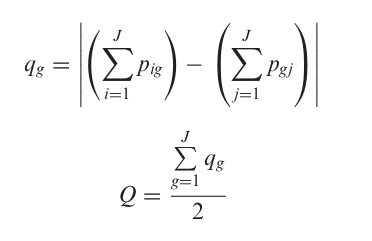

In [ ]:
QD = (np.abs(total_ref - total_class)).sum() / 2
QD

logo erro de alocação é 

In [ ]:
EG - QD

vamos aqui usar pela formula

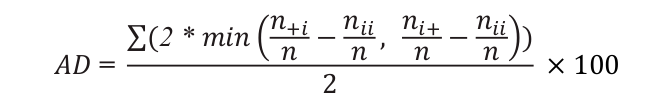

In [ ]:
menor_diferenca = np.minimum((total_class - concordancia), (total_ref - concordancia))
menor_diferenca

In [ ]:
AD = ((menor_diferenca * 2).sum() / 2) 
AD

### Indice Kappa

In [ ]:
from sklearn.metrics import cohen_kappa_score

In [ ]:
kappa = cohen_kappa_score(y_true, y_pred)
kappa

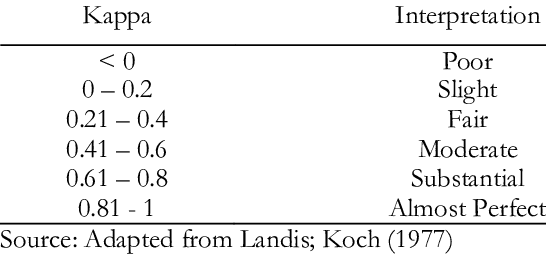

### Com estimativa de área

#### Preparacao

a probabilidade, que é a quantidade de amostras sobre a populacão, e esta salva com ajustes de acordo com o voto em peso_voto

ver os valores antes desse ajuste

In [ ]:
df_acc['PESO_VOT'].describe()

In [ ]:
biomes = df_acc['BioNB'].unique()
biomes

acho que é feito por biomas, pq em alguns biomas eles usam dados da validacao no treinamento

aqui eu corrigi o codigo que estava em  https://github.com/mapbiomas-brazil/accuraccy/blob/mapbiomas80/src/estimates_codes/2_accuracy_estimates.py, para de fato excluir as amostras que foram usadas no treinamento. La nao esta excluindo por erro de digitacao, 'treinamento'

In [ ]:
for biome in biomes:
        print ("biome", biome)
        biome_filter = (df_acc['BioNB'] == biome)
        n_samples, _ = df_acc[biome_filter & (df_acc['AMOSTRAS'] != 'treinamento')].shape
        t_samples, _ = df_acc[biome_filter].shape
        print ("amostras sem treinamento", n_samples, "amostras com treinamento", t_samples)
        prob_biome_adjs = n_samples / t_samples
        df_acc.loc[biome_filter, 'PESO_VOT'] = df_acc[biome_filter]['PESO_VOT'] * prob_biome_adjs

In [ ]:
#df_acc = df_acc[df_acc['AMOSTRAS'] != 'Treinamento']

In [ ]:
df_acc['PESO_VOT'].describe()

In [ ]:
sample_weight = 1 / df_acc[['PESO_VOT']].to_numpy().flatten()
population = sample_weight.sum()


In [ ]:
len(sample_weight)

In [ ]:
population

In [ ]:
matrix_ponderada = confusion_matrix(y_true, y_pred, sample_weight=sample_weight/population)

In [ ]:
matrix_ponderada = matrix_ponderada.T
print (matrix_ponderada)

In [ ]:
df_matriz = pd.DataFrame(matrix_ponderada, columns=class_names, index=class_names)
df_matriz

### Calculo da acuracia

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score

In [ ]:
total = df_matriz.sum().sum()
total

In [ ]:
concordancia = np.diag(df_matriz.values)
concordancia

In [ ]:
total_class= df_matriz.sum(axis=1)
total_class

In [ ]:
total_ref = df_matriz.sum(axis=0)
total_ref

In [ ]:
total_concordancia  = concordancia.sum()
total_concordancia

#### Acuracia Global

In [ ]:
AG = total_concordancia
AG

#### Erro Global

In [ ]:
EG = 1 - AG
EG

#### Acuracia do consumidor e erros de comissao

In [ ]:
AC = concordancia / total_class
AC.sort_values(ascending=False)

aqui estou fazendo o equivalente ao micro

In [ ]:
concordancia.sum() / total_class.sum()

Micro: Calcula a métrica globalmente.
Macro: Calcula a métrica para cada classe e depois tira a média.
Weighted: Calcula a métrica para cada classe e tira a média ponderada pelo suporte de cada classe.

In [ ]:
precision_score(y_true, y_pred, average='micro')

In [ ]:
EC = 1 - AC
EC.sort_values(ascending=False)

In [ ]:
1 - concordancia.sum() / total_class.sum()

#### Acuracia do produtor e erros de omissao

In [ ]:
AP = concordancia / total_ref
AP.sort_values(ascending=False)

In [ ]:
concordancia.sum() / total_ref.sum()

In [ ]:
recall_score(y_true, y_pred, average='micro')

In [ ]:
EO = 1 - AP
EO

#### F1 Score

In [ ]:
f1_score(y_true, y_pred, average='micro')

#### Erro de quantidade (area disagrement)



In [ ]:
QD = (np.abs(total_ref - total_class)).sum() / 2
QD

logo erro de alocação é 

In [ ]:
EG - QD

In [ ]:
menor_diferenca = np.minimum((total_class - concordancia), (total_ref - concordancia))
menor_diferenca

In [ ]:
AD = ((menor_diferenca * 2).sum() / 2) 
AD

### Indice Kappa

In [ ]:
from sklearn.metrics import cohen_kappa_score

In [ ]:
kappa = cohen_kappa_score(y_true, y_pred)
kappa

## Visualização geográfica

In [ ]:
df_acc.columns

In [ ]:
import geopandas as gpd
from shapely.geometry import Point

In [ ]:
geometry = [Point(xy) for xy in zip(df_acc['LON'], df_acc['LAT'])]

In [ ]:
gdf = gpd.GeoDataFrame(df_acc, geometry=geometry)

In [ ]:
# Definindo o sistema de coordenadas (CRS) - aqui, WGS84 (epsg:4326)
gdf.set_crs(epsg=4326, inplace=True)

In [ ]:
gdf_erros = gdf[gdf['classification'] != gdf['reference']]
gdf_erros.shape

In [ ]:
gdf_erros.drop('system:index', axis=1, inplace=True)

In [ ]:
gdf_erros.drop('.geo', axis=1, inplace=True)

In [ ]:
gdf_erros

In [ ]:
gdf_erros.plot()

In [ ]:
gdf_erros.to_file("../tmp/pontos_amostrais_erro.shp")